# 06 — Alocação clássica sob incerteza (MILP + CVaR)
Execuções **06A** (configuração B) e **06B** (configuração C) com **a mesma formulação**, sem misturar B e C numa única distribuição.

**Formulação** (`src/optimization/`): plano mensal de alocação `a[k,t]` (urbano, irrigação), **idêntico em todos os cenários** (primeiro estágio). A entrega real segue uma regra implementável, sem antever o futuro: urbano primeiro, depois irrigação, limitada pela água acima do volume morto. Perda do cenário `L = Σ w_k Σ_t (D_kt − y_kt)`. Objetivo: `(1−λ)·E[L] + λ·CVaR_α(L)`, α = 0,8.

**Hipóteses (não são observações):** demandas (urbano 1,5 m³/s; irrigação 3–5 m³/s), pesos setoriais (urbano 3 × irrigação), volume morto = 109,78 hm³ (menor volume observado; limite superior empírico), evaporação fixa ao longo de uma trajetória de referência, pesos **iguais entre anos históricos** (suposição, não probabilidade). **Os resultados valem para essas hipóteses.**

In [1]:
import sys, json; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data.loaders import load_portal_volume
from src.hydrology.evaporation import load_power, penman_open_water_mm
from src.scenarios.generator import ScenarioGenerator
from src.scenarios import synthetic as S
from src.optimization.problem import make_instance
from src.optimization.classical.milp import solve_milp
from src.optimization.classical.baselines import plan_demand, plan_linear, plan_priority
from src.evaluation.metrics import summarize, simulate_plan

vol = load_portal_volume('../data/reserv-ors-capac-175236-portal-hidrologico-ce.csv')
met = load_power('../data/raw/meteo/nasa_power_oros_daily.json'); met['E_mm_day'] = penman_open_water_mm(met)
gen = ScenarioGenerator(vol, met)
CFGS = {'B': S.CONFIG_B, 'C': S.CONFIG_C}
S0S, DEMS, LAMS, ALPHA = [200, 300, 450], [1, 2], [0.0, 0.5, 0.9], 0.8
SEQ = {k: gen.inflow_sequences(c) for k, c in CFGS.items()}
for k in SEQ: print(k, 'anos na amostra:', sorted(SEQ[k].year.unique()))

B anos na amostra: [np.int32(2007), np.int32(2014), np.int32(2015), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024)]
C anos na amostra: [np.int32(2007), np.int32(2012), np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024)]


## 0. Por que estes níveis de armazenamento inicial?
Com armazenamento ≥ 300 hm³ e demanda base não há escassez (déficit nulo para qualquer plano): o problema só é não trivial perto do **estado de seca observado em 2017–2019 (Jul-1: 201–230 hm³)**. Por isso S₀ ∈ {200, 300, 450} hm³ e demanda ×1 (base) e ×2 (estresse hipotético).

In [2]:
rows = []
def run(cfgkey, s0, dem, lam=None, seq=None, v_dead=None, tag='main', years=None):
    cfg = CFGS[cfgkey]; seq = SEQ[cfgkey] if seq is None else seq
    inst = make_instance(seq, cfg, s0, f'{cfgkey}_{s0}_{dem}', demand_scale=dem, v_dead=v_dead, years=years)
    return inst
for ck in CFGS:
    for s0 in S0S:
        for dem in DEMS:
            inst = run(ck, s0, dem)
            for name, a in (('demanda', plan_demand(inst)), ('E01 linear', plan_linear(inst)), ('E02 prioritário', plan_priority(inst))):
                rows.append(dict(cfg=ck, s0=s0, dem=dem, method=name, lam=np.nan, **summarize(inst, a, ALPHA), optimal=True))
            for lam in LAMS:
                r = solve_milp(inst, lam, ALPHA)
                rows.append(dict(cfg=ck, s0=s0, dem=dem, method=f'MILP λ={lam}', lam=lam, **summarize(inst, r['a'], ALPHA), optimal=r['optimal']))
res = pd.DataFrame(rows); res.to_csv('../results/exp06_main_results.csv', index=False)
print('MILPs não ótimos:', int((~res.optimal).sum()), 'de', len(res))
res[(res.cfg == 'B') & (res.dem == 2)][['s0', 'method', 'exp_deficit_urban_pct', 'exp_deficit_irrig_pct', 'exp_loss', 'cvar_loss', 'reliability_all', 'exp_final_storage_hm3']].round(2)

MILPs não ótimos: 0 de 72


,s0,method,exp_deficit_urban_pct,exp_deficit_irrig_pct,exp_loss,cvar_loss,reliability_all,exp_final_storage_hm3
6,200,demanda,32.31,47.52,106.58,137.40,0.00,107.38
7,200,E01 linear,47.69,49.47,131.06,146.41,0.00,117.20
8,200,E02 prioritário,6.37,65.05,91.74,111.01,0.00,117.28
9,200,MILP λ=0.0,0.58,67.78,86.91,99.01,0.00,117.98
10,200,MILP λ=0.5,0.00,68.90,87.51,96.27,0.00,119.13
11,200,MILP λ=0.9,0.00,68.90,87.51,96.27,0.00,119.13
18,300,demanda,1.80,5.96,10.15,25.84,0.45,118.07
19,300,E01 linear,1.78,6.02,10.20,25.65,0.00,118.13
20,300,E02 prioritário,1.70,6.05,10.12,25.58,0.00,118.13
21,300,MILP λ=0.0,0.57,7.11,9.84,22.03,0.00,118.93


## 06A — configuração B (demanda ×1 e ×2)

In [3]:
cols = ['s0', 'dem', 'method', 'exp_deficit_urban_pct', 'exp_deficit_irrig_pct', 'exp_loss', 'cvar_loss', 'reliability_all', 'exp_final_storage_hm3']
res[(res.cfg == 'B') & (res.s0 <= 300) & (res.dem == 1)][cols].round(2)

,s0,dem,method,exp_deficit_urban_pct,exp_deficit_irrig_pct,exp_loss,cvar_loss,reliability_all,exp_final_storage_hm3
0,200,1,demanda,0.78,4.88,3.65,10.78,0.55,122.25
1,200,1,E01 linear,0.78,4.88,3.65,10.78,0.55,122.25
2,200,1,E02 prioritário,0.78,4.88,3.65,10.78,0.55,122.25
3,200,1,MILP λ=0.0,0.78,4.88,3.65,10.78,0.55,122.25
4,200,1,MILP λ=0.5,0.00,6.93,4.40,8.92,0.00,123.37
5,200,1,MILP λ=0.9,0.00,6.93,4.40,8.92,0.00,123.37
12,300,1,demanda,0.00,0.00,0.00,0.00,1.00,196.98
13,300,1,E01 linear,0.00,0.00,0.00,0.00,1.00,196.98
14,300,1,E02 prioritário,0.00,0.00,0.00,0.00,1.00,196.98
15,300,1,MILP λ=0.0,0.00,0.00,0.00,0.00,1.00,196.98


## 06B — configuração C (mesma formulação, mesmos parâmetros)

In [4]:
res[(res.cfg == 'C') & (res.s0 <= 300) & (res.dem == 2)][cols].round(2)

,s0,dem,method,exp_deficit_urban_pct,exp_deficit_irrig_pct,exp_loss,cvar_loss,reliability_all,exp_final_storage_hm3
42,200,2,demanda,10.98,21.00,42.38,117.83,0.23,114.39
43,200,2,E01 linear,22.73,25.82,65.31,121.38,0.00,126.12
44,200,2,E02 prioritário,8.70,31.09,51.93,111.41,0.00,126.12
45,200,2,MILP λ=0.0,8.98,22.40,41.30,112.51,0.00,115.22
46,200,2,MILP λ=0.5,8.70,22.74,41.33,111.41,0.00,115.52
47,200,2,MILP λ=0.9,1.30,56.63,73.78,94.28,0.00,155.03
54,300,2,demanda,2.85,4.23,9.44,37.39,0.69,153.25
55,300,2,E01 linear,2.85,4.23,9.44,37.39,0.69,153.25
56,300,2,E02 prioritário,2.85,4.23,9.44,37.39,0.69,153.25
57,300,2,MILP λ=0.0,2.85,4.23,9.44,37.39,0.69,153.25


## 1. Fronteira risco–perda (sensibilidade a λ)

,cfg,s0,dem,lam,exp_loss,cvar_loss,exp_deficit_urban_pct,exp_deficit_irrig_pct
6,B,200,2,0.00,86.91,99.01,0.58,67.78
7,B,200,2,0.25,87.51,96.27,0.00,68.90
8,B,200,2,0.50,87.51,96.27,0.00,68.90
9,B,200,2,0.75,87.51,96.27,0.00,68.90
10,B,200,2,0.90,87.51,96.27,0.00,68.90
11,B,200,2,1.00,88.25,96.27,0.00,69.48
24,C,200,2,0.00,41.30,112.51,8.98,22.40
25,C,200,2,0.25,41.33,111.41,8.70,22.74
26,C,200,2,0.50,41.33,111.41,8.70,22.74
27,C,200,2,0.75,73.78,94.28,1.30,56.63


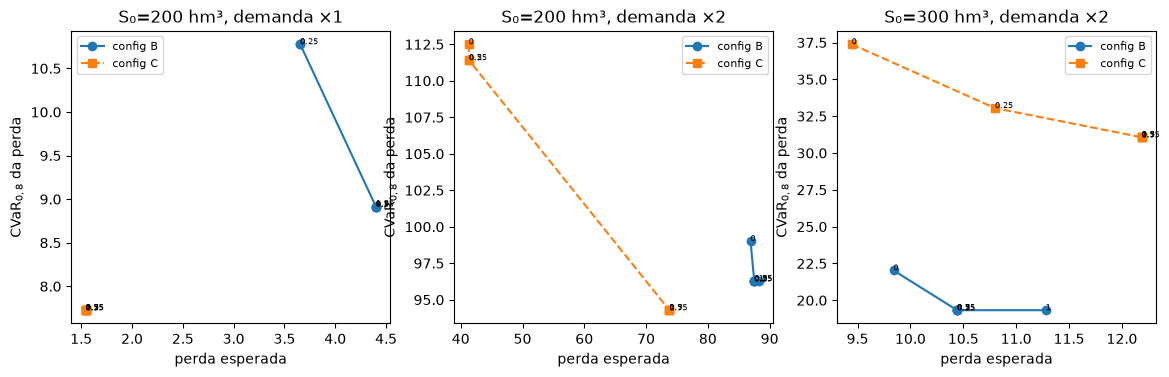

In [5]:
LAM_GRID = [0, 0.25, 0.5, 0.75, 0.9, 1.0]
fr = []
for ck in CFGS:
    for s0, dem in [(200, 1), (200, 2), (300, 2)]:
        inst = run(ck, s0, dem)
        for lam in LAM_GRID:
            r = solve_milp(inst, lam, ALPHA); fr.append(dict(cfg=ck, s0=s0, dem=dem, lam=lam, plan=r['a'], **summarize(inst, r['a'], ALPHA)))
fr = pd.DataFrame(fr)
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (s0, dem) in zip(axs, [(200, 1), (200, 2), (300, 2)]):
    for ck, mk in (('B', 'o-'), ('C', 's--')):
        d = fr[(fr.cfg == ck) & (fr.s0 == s0) & (fr.dem == dem)]
        ax.plot(d.exp_loss, d.cvar_loss, mk, label=f'config {ck}')
        for _, r_ in d.iterrows(): ax.annotate(f'{r_.lam:g}', (r_.exp_loss, r_.cvar_loss), fontsize=6)
    ax.set_xlabel('perda esperada'); ax.set_ylabel('CVaR$_{0,8}$ da perda'); ax.set_title(f'S₀={s0} hm³, demanda ×{dem}'); ax.legend(fontsize=8)
fig.savefig('../results/figures/06_risk_frontier.png', dpi=150, bbox_inches='tight')
fr.drop(columns='plan')[['cfg', 's0', 'dem', 'lam', 'exp_loss', 'cvar_loss', 'exp_deficit_urban_pct', 'exp_deficit_irrig_pct']].round(2).query('s0==200 and dem==2')

## 2. Robustez B × C: o plano ótimo de uma hipótese avaliado na outra
Mesma S₀, mesma demanda, λ = 0,5. **Arrependimento** = objetivo do plano de B avaliado em C menos o objetivo do plano de C em C (e vice-versa). As amostras de anos diferem (B: 11 anos; C: 13), então a comparação mistura hipótese e amostra.

In [6]:
def obj(inst, a, lam=0.5):
    s = summarize(inst, a, ALPHA); return (1 - lam) * s['exp_loss'] + lam * s['cvar_loss']
rg = []
for s0, dem in [(200, 1), (200, 2), (300, 2), (450, 2)]:
    iB, iC = run('B', s0, dem), run('C', s0, dem)
    aB, aC = solve_milp(iB, 0.5, ALPHA)['a'], solve_milp(iC, 0.5, ALPHA)['a']
    rg.append(dict(s0=s0, dem=dem, obj_B_planB=obj(iB, aB), obj_B_planC=obj(iB, aC), obj_C_planC=obj(iC, aC), obj_C_planB=obj(iC, aB),
                   plan_distance_hm3=float(np.abs(aB - aC).sum()), total_demand_hm3=float(iB.D.sum()),
                   B_urban_planned_pct=100 * aB[0].sum() / iB.D[0].sum(), B_irrig_planned_pct=100 * aB[1].sum() / iB.D[1].sum(),
                   C_urban_planned_pct=100 * aC[0].sum() / iC.D[0].sum(), C_irrig_planned_pct=100 * aC[1].sum() / iC.D[1].sum()))
rg = pd.DataFrame(rg); rg['regret_planC_in_B'] = rg.obj_B_planC - rg.obj_B_planB; rg['regret_planB_in_C'] = rg.obj_C_planB - rg.obj_C_planC
rg.round(2)

,s0,dem,obj_B_planB,obj_B_planC,obj_C_planC,obj_C_planB,plan_distance_hm3,total_demand_hm3,B_urban_planned_pct,B_irrig_planned_pct,C_urban_planned_pct,C_irrig_planned_pct,regret_planC_in_B,regret_planB_in_C
0,200,1,6.66,7.22,4.64,6.68,2.05,87.35,100.0,96.77,100.0,100.00,0.56,2.05
1,200,2,91.89,122.36,76.37,91.07,76.85,174.70,100.0,35.94,100.0,96.45,30.47,14.70
2,300,2,14.88,15.27,21.63,21.82,10.52,174.70,100.0,96.52,100.0,95.20,0.38,0.19
3,450,2,0.00,0.00,0.00,0.00,0.00,174.70,100.0,100.00,100.0,100.00,0.00,0.00


## 3. Sensibilidade à seleção (meses com afluência implícita negativa)
Política `exclude` (padrão): anos com algum mês de afluência implícita negativa ficam fora. Política `floor_at_zero`: esses meses entram com afluência **truncada em 0** (marcados). Se as conclusões mudarem, dependem da seleção.

In [7]:
sel = []
for ck in CFGS:
    seq_f = gen.inflow_sequences(CFGS[ck], 'floor_at_zero')
    print(ck, 'anos exclude:', SEQ[ck].year.nunique(), '| floor_at_zero:', seq_f.year.nunique(), '| meses truncados:', int(seq_f.floored.sum()))
    for s0, dem in [(200, 1), (200, 2), (300, 2)]:
        for pol, sq in (('exclude', SEQ[ck]), ('floor_at_zero', seq_f)):
            inst = run(ck, s0, dem, seq=sq); r = solve_milp(inst, 0.5, ALPHA)
            sel.append(dict(cfg=ck, s0=s0, dem=dem, policy=pol, n_years=inst.n_scen, **{k: v for k, v in summarize(inst, r['a'], ALPHA).items() if k in ('exp_loss', 'cvar_loss', 'exp_deficit_urban_pct', 'exp_deficit_irrig_pct')},
                            plan_urban_pct=100 * r['a'][0].sum() / inst.D[0].sum(), plan_irrig_pct=100 * r['a'][1].sum() / inst.D[1].sum()))
sel = pd.DataFrame(sel); sel.round(2)

B anos exclude: 11 | floor_at_zero: 13 | meses truncados: 4


C anos exclude: 13 | floor_at_zero: 13 | meses truncados: 0


,cfg,s0,dem,policy,n_years,exp_loss,cvar_loss,exp_deficit_urban_pct,exp_deficit_irrig_pct,plan_urban_pct,plan_irrig_pct
0,B,200,1,exclude,11,4.40,8.92,0.00,6.93,100.0,96.77
1,B,200,1,floor_at_zero,13,10.20,34.73,5.10,10.32,100.0,96.77
2,B,200,2,exclude,11,87.51,96.27,0.00,68.90,100.0,35.94
3,B,200,2,floor_at_zero,13,94.73,125.88,2.51,71.76,100.0,35.94
4,B,300,2,exclude,11,10.44,19.33,0.00,8.22,100.0,96.52
5,B,300,2,floor_at_zero,13,17.36,47.36,2.59,10.75,100.0,96.52
6,C,200,1,exclude,13,1.55,7.73,1.30,0.97,100.0,100.00
7,C,200,1,floor_at_zero,13,1.55,7.73,1.30,0.97,100.0,100.00
8,C,200,2,exclude,13,41.33,111.41,8.70,22.74,100.0,96.45
9,C,200,2,floor_at_zero,13,41.33,111.41,8.70,22.74,100.0,96.45


## 4. Sensibilidade ao volume morto (0 × 109,78 hm³)

In [8]:
vd = []
for ck in CFGS:
    for s0, dem in [(200, 1), (200, 2), (300, 2)]:
        for v in (0.0, 109.78):
            inst = run(ck, s0, dem, v_dead=v); r = solve_milp(inst, 0.5, ALPHA); sm = summarize(inst, r['a'], ALPHA)
            vd.append(dict(cfg=ck, s0=s0, dem=dem, v_dead=v, exp_loss=sm['exp_loss'], cvar_loss=sm['cvar_loss'],
                           plan_urban_pct=100 * r['a'][0].sum() / inst.D[0].sum(), plan_irrig_pct=100 * r['a'][1].sum() / inst.D[1].sum()))
pd.DataFrame(vd).round(2)

,cfg,s0,dem,v_dead,exp_loss,cvar_loss,plan_urban_pct,plan_irrig_pct
0,B,200,1,0.00,0.00,0.00,100.0,100.00
1,B,200,1,109.78,4.40,8.92,100.0,96.77
2,B,200,2,0.00,0.00,0.00,100.0,100.00
3,B,200,2,109.78,87.51,96.27,100.0,35.94
4,B,300,2,0.00,0.00,0.00,100.0,100.00
5,B,300,2,109.78,10.44,19.33,100.0,96.52
6,C,200,1,0.00,0.00,0.00,100.0,100.00
7,C,200,1,109.78,1.55,7.73,100.0,100.00
8,C,200,2,0.00,0.44,2.22,100.0,100.00
9,C,200,2,109.78,41.33,111.41,100.0,96.45


## 5. Validação fora da amostra (leave-one-year-out)
Para cada ano histórico: otimizar (ou calcular o plano de referência) com os **demais** anos e avaliar no ano omitido. Compara MILP (λ = 0,5) com as referências, usando a mesma regra de avaliação. n pequeno: **evidência exploratória**, não estatística.

In [9]:
def loyo(ck, s0, dem, lam=0.5):
    cfg, seq = CFGS[ck], SEQ[ck]; ys = sorted(seq.year.unique()); out = {m: [] for m in ('MILP', 'E01 linear', 'E02 prioritário', 'demanda')}
    for h in ys:
        tr = [y for y in ys if y != h]
        itr = make_instance(seq, cfg, s0, 'tr', demand_scale=dem, years=tr); ite = make_instance(seq, cfg, s0, 'te', demand_scale=dem, years=[h])
        plans = {'MILP': solve_milp(itr, lam, ALPHA)['a'], 'E01 linear': plan_linear(itr), 'E02 prioritário': plan_priority(itr), 'demanda': plan_demand(itr)}
        for m, a in plans.items(): out[m].append(simulate_plan(ite, a)['loss'][0])
    return pd.DataFrame(out, index=ys)
lo = []
for ck in CFGS:
    for s0, dem in [(200, 1), (200, 2), (300, 2)]:
        L = loyo(ck, s0, dem)
        for m in L: 
            v = np.sort(L[m].values)[::-1]; k = max(1, int(np.ceil(0.2 * len(v))))
            lo.append(dict(cfg=ck, s0=s0, dem=dem, method=m, mean_heldout_loss=v.mean(), worst_heldout=v[0], tail20_mean=v[:k].mean(), n=len(v)))
lo = pd.DataFrame(lo); lo.round(2).pivot_table(index=['cfg', 's0', 'dem'], columns='method', values='mean_heldout_loss')

method       E01 linear  E02 prioritário   MILP  demanda
cfg s0  dem                                             
B   200 1          3.65             3.65   4.77     3.65
        2        131.79            92.39  87.89   106.58
    300 2         11.55            11.05  10.81    10.15
C   200 1          1.55             1.55   1.55     1.55
        2         67.19            53.52  41.37    42.38
    300 2          9.44             9.44  12.58     9.44

In [10]:
lo.round(2).pivot_table(index=['cfg', 's0', 'dem'], columns='method', values='tail20_mean')

method       E01 linear  E02 prioritário    MILP  demanda
cfg s0  dem                                              
B   200 1          9.91             9.91    9.91     9.91
        2        144.23           109.84   97.27   136.97
    300 2         24.76            24.76   20.33    24.76
C   200 1          6.70             6.70    6.70     6.70
        2        118.77           110.81  110.98   117.31
    300 2         35.95            35.95   31.25    35.95

In [11]:
res.to_csv('../results/exp06_main_results.csv', index=False); rg.to_csv('../results/exp06_robustness_BxC.csv', index=False)
sel.to_csv('../results/exp06_selection_sensitivity.csv', index=False); pd.DataFrame(vd).to_csv('../results/exp06_dead_volume_sensitivity.csv', index=False)
lo.to_csv('../results/exp06_leave_one_year_out.csv', index=False); fr.drop(columns='plan').to_csv('../results/exp06_risk_frontier.csv', index=False)
print('salvo')

salvo


## Interpretação e limites
Preenchida no relatório (seção 4.6) após leitura dos números acima. Em todos os casos: demandas, pesos, volume morto e E de referência são **hipóteses**; B e C são **provisórias**; resultados **não validam** o balanço hídrico nem constituem recomendação operacional.